# 1D Unsteady Heat Conduction in a Rod
### CFD Assignment 3

Juliano B12202031

Complete source code (frozen for this assignment): [github.com/anojewel/siefdi/tree/assignment-3](https://github.com/anojewel/siefdi/tree/assignment-3)

[🤖CLAUDE] in the docstring because I'm too lazy to write docstring

## Problem statement

A thin plate is initially at a uniform temperature of $200\,{}^\circ\mathrm{C}$. At a certain time $t = 0\,\mathrm{s}$ the temperature of the east side of the plate is suddenly reduced to $0\,{}^\circ\mathrm{C}$. The other side of the surface is insulated. Use the **explicit finite volume method** with a suitable time step size to calculate the transient temperature distribution of this slab and compare with the analytical solution at time (i) $t = 40\,\mathrm{s}$, (ii) $t = 80\,\mathrm{s}$ and (iii) $t = 120\,\mathrm{s}$.

Length of the plate is $L = 2\,\mathrm{cm}$, thermal conductivity is $k = 10\,\mathrm{W/(m\,K)}$, and $\rho c = 10 \times 10^6\,\mathrm{J/(m^3\,K)}$.

The one-dimensional transient heat conduction problem is governed by
$$ \rho c \frac{\partial T}{\partial t} = \frac{\partial}{\partial x}\left(k \frac{\partial T}{\partial x}\right) $$

The analytical solution is given in Ozisik (1985) as
$$ \frac{T(x,t)}{200} = \frac{4}{\pi} \sum_{n=1}^{\infty} \frac{(-1)^{n+1}}{2n-1} \exp\left(-\alpha \lambda_n^2 t\right) \cos\left(\lambda_n x\right) $$
$$ \lambda_n = \frac{(2n-1)\pi}{2L}, \qquad \alpha = \frac{k}{\rho c} $$

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import inspect
import matplotlib.pyplot as plt

from src.geometry import RectangleSpace, CellCentredGrid
from src.fields import InternalScalarField, SimpleWallBC
from src.fvm import Diffusion, Transient, ExplicitMarch
from src.matrix_solver import SystemLinearEquations

We make the 1D rod using syntax similar to Assignment 1.

In [2]:
# L = 2cm and mesh, limit it to 5 nodes so it's easier to read:
rod_gridded = RectangleSpace([[0,0.02],[0,0.1],[0,0.1]]).grid('cell',[5])
# Insulated west wall plus the east wall held 0:
heated_ends = SimpleWallBC(
    wall_values = [[0,0],[0,0],[0,0]],
    derivative_order= [[1,0],[1,1],[1,1]]
)
rod_temp = InternalScalarField(
    grid=rod_gridded,
    bcs=heated_ends,
    values=200 * np.ones(rod_gridded.shape[0])
)
# Store the diffusion term, k= 10 is stored here
rod_diffusion_term = Diffusion(rod_temp, 10)

**Index convention.** Nodes (cell centres) get whole-number indices: $T_i$ is the temperature at node $x_i$, the centre of cell $i$. Faces sit halfway between nodes and get half indices: cell $i$ spans from its west face $x_{i-1/2}$ to its east face $x_{i+1/2}$.

Two different lengths follow from this:
- $\Delta x = x_{i+1/2} - x_{i-1/2}$: face to face, the width of cell $i$.
- $(\delta x)_{i+1/2} = x_{i+1} - x_i$: node to node, the distance across face $i+1/2$. At a wall it is only half a cell.
- $\Delta V = A\,\Delta x$: the volume of cell $i$, with $A$ the cross-section area of the rod.

$T_0$ and $T_{N+1}$ are the wall values, located on the wall faces $x_{1/2}$ and $x_{N+1/2}$; the half-cell distance is in $D_{1/2}$ and $D_{N+1/2}$.

These values are stored in the modules of the `Grid` in `geometry.py`. `[0]` to just show the $x$ dimension:

In [3]:
print("faces   x_{i±1/2}:", rod_gridded.faces[0])
print("nodes   x_i      :", rod_gridded.centres[0])
print("δx      (centre_spacing):", rod_gridded.centre_spacing[0])
print("Δx      (cell_lengths)  :", rod_gridded.cell_lengths[0])

faces   x_{i±1/2}: [0.    0.004 0.008 0.012 0.016 0.02 ]
nodes   x_i      : [0.002 0.006 0.01  0.014 0.018]
δx      (centre_spacing): [0.002 0.004 0.004 0.004 0.004 0.002]
Δx      (cell_lengths)  : 0.004


### Governing equation

We take a thin slice of the plate between $x$ and $x+dx$, with cross-section area $A$. There is no heat source inside, so energy conservation says the rate of change of the energy stored in the slice equals the heat flowing in minus the heat flowing out:
$$ \frac{\partial}{\partial t}\left(\rho c\,T\,A\,dx\right) = q(x)\,A - q(x+dx)\,A $$
where $q$ is the heat flux in the $+x$ direction. $\rho c$, $A$ and $dx$ are constant, so they come out of the time derivative. Taylor expanding $q(x+dx) \approx q(x) + \dfrac{\partial q}{\partial x}dx$:
$$ \rho c \frac{\partial T}{\partial t} A\,dx = -\frac{\partial q}{\partial x} A\,dx \implies \rho c \frac{\partial T}{\partial t} = -\frac{\partial q}{\partial x} $$
Fourier's law relates the flux to the temperature gradient (heat flows from hot to cold, hence the minus sign):
$$ q = -k\frac{\partial T}{\partial x} $$
Substituting it in:
$$ \rho c \frac{\partial T}{\partial t} = \frac{\partial}{\partial x}\left(k \frac{\partial T}{\partial x}\right) $$
which is the governing equation given in the problem.

Now we begin the discretization. We integrate over each finite volume, from the west face $x_{i-1/2}$ to the east face $x_{i+1/2}$ of cell $i$ (the diffusion coefficient and the cross-section area $A$ are constant).

$$ \rho c A \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial T}{\partial t} dx' = kA \left[ \left(\frac{\partial T}{\partial x}\right)_{i+1/2} - \left(\frac{\partial T}{\partial x}\right)_{i-1/2} \right]$$


Use central difference assuming piecewise-linear profile $\left(\frac{\partial T}{\partial x}\right)_{i+1/2} \approx \frac{T_{i+1} - T_i}{(\delta x)_{i+1/2}}$:
$$ \rho c A \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial T}{\partial t} dx' = kA\left[ \frac{T_{i+1} - T_i}{x_{i+1}- x_i} - \frac{T_i - T_{i-1}}{x_i - x_{i-1}}\right ] $$
$$ \rho c A \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial T}{\partial t} dx' = kA \left[ \frac{T_{i+1}}{(\delta x)_{i+1/2}} +\frac{T_{i-1}}{(\delta x)_{i-1/2}} - T_i \left( \frac {1}{(\delta x)_{i-1/2}} +\frac{1}{(\delta x)_{i+1/2}}\right)\right]$$


FVM rule assumes that $T$ is constant over each grid (face to face):
$$\rho c A \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial T}{\partial t} dx' = \rho c \frac{\partial T_i}{\partial t} A\,(x_{i+1/2}-x_{i-1/2}) =\rho c \frac{\partial T_i}{\partial t} \Delta V $$
$$\implies \rho c \frac{\partial T_i}{\partial t} \Delta V = kA \left[ \frac{T_{i+1}}{(\delta x)_{i+1/2}} +\frac{T_{i-1}}{(\delta x)_{i-1/2}} - T_i \left( \frac {1}{(\delta x)_{i-1/2}} +\frac{1}{(\delta x)_{i+1/2}}\right)\right]$$

Now define the face conductances:
$$
D_{i\pm1/2} = \frac{kA}{(\delta x)_{i\pm1/2}}
$$

$D_i$ is stored in `Diffusion.conductances`.

In [4]:
print(inspect.getsource(Diffusion.conductances))

    def conductances(self):
        """🤖 [CLAUDE] Diffusion conductance D = Γ·A/δx of every face, per axis.

        Returns:
            list[np.ndarray]: One array per axis with N+1 entries for N cells,
            laid out like ``grid.centre_spacing``. Entry ``i`` belongs to face
            ``i``: the first and last are wall faces (δx is half a cell), and
            the rest are interior faces (δx is centre to centre).
        """
        target_list = []
        g = self.field.grid
        for axis in range(g.dim):
            ### ↓ THE FORMULA ↓ ###
            singledim_diffusion_conductances = (self.coefficient * g.areas[axis]) * (1/g.centre_spacing[axis])
            target_list.append(singledim_diffusion_conductances)
        return target_list



In [5]:
print(f"D_i face conductances: {rod_diffusion_term.conductances()[0]}")

D_i face conductances: [50. 25. 25. 25. 25. 50.]


On the uniform grid ($\Delta x = 4\,\mathrm{mm}$, $A = 0.01\,\mathrm{m^2}$) these are the numbers printed above:

$$
D_{0.5} = D_{5.5} = \frac{kA}{\Delta x/2} = 50\,\mathrm{W/K}, \qquad
D_{1.5} = D_{2.5} = D_{3.5} = D_{4.5} = \frac{kA}{\Delta x} = 25\,\mathrm{W/K}
$$

The two wall faces are twice as large because the wall is only half a cell from its node.

The equation becomes:
$$\rho c\,\Delta V\,\frac{\partial T_i}{\partial t} = D_{i+1/2}T_{i+1} + D_{i-1/2}T_{i-1} - (D_{i-1/2}+D_{i+1/2})\,T_i$$

We cannot yet build a square matrix out of this before taking a look at the walls. First for Neumann BCS, the problem states that the west wall is insulated ($\partial_x T = 0$). But to maintain generalization for the code, I won't substitute $0$ here.

 Thus, at the west face:
$$ \left(\frac{\partial T}{\partial x}\right)_{0.5} = \frac{T_1 - T_{0}}{(\delta x)_{0.5}} \implies T_{1} - T_0 = \left(\frac{\partial T}{\partial x}\right)_{0.5} (\delta x)_{0.5}$$


Thus, for the first equation ($i=1$)
$$
\begin{aligned}
\rho c \Delta V \dfrac{\partial T_1}{\partial t}&=D_{1.5}T_{2} + D_{0.5}T_{0} -(D_{0.5} + D_{1.5}) T_1\\
&=D_{1.5}T_2 + D_{0.5}(T_{0} - T_1) -D_{1.5} T_1\\
&=D_{1.5}T_2 -D_{0.5 }\left(\frac{\partial T}{\partial x}\right)_{0.5} (\delta x)_{0.5} - D_{1.5} T_1
\end{aligned}
$$
Since $D_{0.5}(\delta x)_{0.5} = \dfrac{kA}{(\delta x)_{0.5}}(\delta x)_{0.5} = kA$, the wall term is just Fourier's law, the heat flowing into cell 1 through the west wall:
$$ -D_{0.5}\left(\frac{\partial T}{\partial x}\right)_{0.5}(\delta x)_{0.5} = -kA\left(\frac{\partial T}{\partial x}\right)_{0.5} $$
For the insulated wall the slope is $0$, so this term vanishes.

$T_0$ has dropped out, so the equation involves only the unknowns $T_1$ and $T_2$. This is one step toward building the square matrix.

The next one is the Dirichlet BCS for the east wall $T_6 = 0$. To maintain generalization, I don't substitute the number. 

For the last equation ($i=5$):
$$
\begin{aligned}
\rho c \Delta V \frac{\partial T_5}{\partial t} &= D_{5.5} T_{6} + D_{4.5}T_4 - (D_{4.5}+D_{5.5})T_5
\end{aligned}
$$
Since $T_6$ is known, $D_{5.5}T_6$ moves into $\vec b$, and the remaining terms involve only the unknowns $T_4$ and $T_5$. This means our $5\times5$ square matrix is ready to be built:


Writing all five equations together:
$$
\rho c\,\Delta V \frac{d}{dt}
\underbrace{\begin{bmatrix} T_1 \\ T_2 \\ T_3 \\ T_4 \\ T_5 \end{bmatrix}}_{\vec{T}}
= -\underbrace{
\begin{bmatrix}
\color{#4493f8} D_{1.5} & \color{#4493f8} -D_{1.5} & \color{#4493f8} 0 & \color{#4493f8} 0 & \color{#4493f8} 0 \\
-D_{1.5} & D_{1.5}+D_{2.5} & -D_{2.5} & 0 & 0 \\
0 & -D_{2.5} & D_{2.5}+D_{3.5} & -D_{3.5} & 0 \\
0 & 0 & -D_{3.5} & D_{3.5}+D_{4.5} & -D_{4.5} \\
\color{#4493f8} 0 & \color{#4493f8} 0 & \color{#4493f8} 0 & \color{#4493f8} -D_{4.5} & \color{#4493f8} D_{4.5}+D_{5.5}
\end{bmatrix}}_{\mathbf A}
\underbrace{\begin{bmatrix} T_1 \\ T_2 \\ T_3 \\ T_4 \\ T_5 \end{bmatrix}}_{\vec{T}}
+ \underbrace{
\begin{bmatrix} \color{#4493f8} -D_{0.5}\left(\frac{\partial T}{\partial x}\right)_{0.5}(\delta x)_{0.5} \\ 0 \\ 0 \\ 0 \\ \color{#4493f8} D_{5.5}\,T_6 \end{bmatrix}}_{\vec b}
$$

The whole right-hand side comes from the diffusion term, so both $\mathbf A$ and $\vec b$ are built by `Diffusion`: `matrix()` gives $\mathbf A$ and `source_vector()` gives $\vec b$. The Neumann boudnary condition modifications are also in here.

In [6]:
print(inspect.getsource(Diffusion.matrix))
print(inspect.getsource(Diffusion.source_vector))

    def matrix(self):
        ### A. Assemble A matrix
        # 1. Take the list for just one dimensional diffusion conductances (x-direction)
        diffconds_1d = self.conductances()[0]
        
        # 2. Make diagonal with A_{ii} = D_{i} + D_{i+1}
        matrix_diagonal = np.diag([diffconds_1d[i] + diffconds_1d[i+1] for i in range(len(diffconds_1d)-1)])

        # 3. Make off diagonal parts
        matrix_up_offdiag = np.diag([-diffconds_1d[i+1] for i in range(len(diffconds_1d)-2)],1)
    
        # 4. Combine them to get our target matrix (our result A)
        A= matrix_diagonal + matrix_up_offdiag + matrix_up_offdiag.T

        # 5. Check for Neumann
        f = self.field
        if f.bcs.derivative_order[0,0] == 1:
            A[0,0] = diffconds_1d[1]
        if f.bcs.derivative_order[0,1] == 1:
            A[-1,-1] = diffconds_1d[-2]

        return A

    def source_vector(self):
        diffconds_1d = self.conductances()[0]
        ### B. Assemble b vector
        # Ge

In [7]:
A = rod_diffusion_term.matrix()
b = rod_diffusion_term.source_vector()
print("A =\n", A)
print("b =", b)

A =
 [[ 25. -25.   0.   0.   0.]
 [-25.  50. -25.   0.   0.]
 [  0. -25.  50. -25.   0.]
 [  0.   0. -25.  50. -25.]
 [  0.   0.   0. -25.  75.]]
b = [-0.  0.  0.  0.  0.]


The whole thing can now be written simply as:
$$\rho c\,\Delta V\,\frac{d\vec{T}}{dt} = -\mathbf{A}\,\vec{T} + \vec{b}$$

- Transient field is stored in `Transient.field`
- $\rho c$ is stored in `Transient.coefficient`

In [8]:
print(inspect.signature(Transient))
# The numbers here 
rod_transient_term = Transient(
    field = rod_temp,
    coefficient = 10**7 # From the Problem Statement.
)

(field, coefficient)


Now we begin the marching solution by integrating from $t$ to $t+\Delta t$. 🤖 Note that $T$ is dependent on both position and time, but the subscripts already denote position, so we only write $T(t)$:

$$ \int_t^{t+\Delta t} \rho c \Delta V \dfrac{d\vec T(t')}{dt'}dt' = \int_t^{t+\Delta t} \left(-\mathbf A \, \vec T(t') + \vec b\right) dt' $$

Setting it up in code, the values are stored in `ExplicitMarch`
- $\Delta t$ is stored in `ExplicitMarch.time_step`
- `Diffusion` and `Transient` objects contain all the fields and coefficients. So they are stored in attributes `ExplicitMarch.diffusion` and `ExplicitMarch.transient`

In [9]:
e_march = ExplicitMarch(
    diffusion= rod_diffusion_term,
    transient= rod_transient_term,
    time_step= 1
)
# Here we pick 1 second as our time step.

From the lectures, the weighted scheme defines the time integral approximation:
$$\int_t^{t+\Delta t} T(t') dt' \approx [f T(t+\Delta t) + (1-f)T(t)]\,\Delta t$$
Where $f$ is the weight. For **explicit scheme** it is $f=0$ so
$\int_t^{t+\Delta t} T(t') dt' \approx T(t)\,\Delta t$. Thus the main equation becomes


$$ \rho c \Delta V \,[\vec{T}(t+\Delta t) - \vec T(t)] = \Delta t \left(-\mathbf A \, \vec T(t) + \vec b\right) $$
$$\vec T(t+\Delta t)= \dfrac{\Delta t}{\rho c \Delta V}\left(-\mathbf A \, \vec T(t) + \vec b\right) + \vec T(t)$$

To find the limit of $\Delta t$, we look at the coefficient of $\vec T(t)$. Using index notation is easier here:
$$T_i(t+\Delta t) = \dfrac{\Delta t}{\rho c \Delta V}[D_{i+1/2}T_{i+1}(t)- (D_{i-1/2}+D_{i+1/2})\,T_i(t) + D_{i-1/2}T_{i-1}(t)] + T_i(t)$$
$$
T_i(t+\Delta t) = \dfrac{\Delta t}{\rho c \Delta V}[D_{i+1/2}T_{i+1}(t)+ D_{i-1/2}T_{i-1}(t)] +\underbrace{[1 - \dfrac{\Delta t}{\rho c \Delta V}(D_{i-1/2}+D_{i+1/2})]}_{\text{must be } \ge 0} T_i(t)
$$

By Patankar's positive-coefficient rule (Rule 2 of his four basic rules for the FVM), every coefficient of the old values must have the same sign as the coefficient of $T_i(t+\Delta t)$, which is $1$, so
$$1 - \dfrac{\Delta t}{\rho c \Delta V}(D_{i-1/2}+D_{i+1/2})>0 \implies  \Delta t < \dfrac{\rho c \Delta V}{D_{i-1/2}+D_{i+1/2}}$$
$(D_{i-1/2}+D_{i+1/2})$ is just the diagonal of $\mathbf A$ so $A_{ii} = D_{i-1/2}+D_{i+1/2}$:
$$\Delta t < \dfrac{\rho c \Delta V}{A_{ii}}$$
It must hold for every $i$, so
$$ \Delta t < \dfrac{\rho c \Delta V}{\max(A_{ii})}$$

This value is stored in the module inside `ExplicitMarch.max_time_step`

For this problem the largest diagonal entry is in the last row, next to the $0\,{}^\circ\mathrm{C}$ wall, where the wall face is only half a cell from the node:

$$
\max_i A_{ii} = A_{55} = D_{4.5} + D_{5.5} = \frac{kA}{\Delta x} + \frac{2kA}{\Delta x} = \frac{3kA}{\Delta x}
$$

With $\rho c\,\Delta V = \rho c\,A\,\Delta x$ the area cancels:

$$
\Delta t < \frac{\rho c\,\Delta x^2}{3k} = \frac{10^7 \cdot (0.004)^2}{3 \cdot 10} = 5.33\,\mathrm{s}
$$

In [10]:
print(inspect.getsource(ExplicitMarch.max_time_step))
print(f"Max time step is {e_march.max_time_step()}")

    def max_time_step(self):
        f = self.diffusion.field
        g = f.grid
        A = self.diffusion.matrix()
        ### TIME LIMIT FORMULA HERE
        return self.transient.coefficient * g.volume / max(np.diag(A))

Max time step is 5.333333333333331


We can see that our time step ($1\text{s}$) is well below the max time step. The value also matches our analytical max time. This check is within the script, it will not run if the time step is too high:

In [11]:
print(inspect.getsource(ExplicitMarch.run))

    def run(self):
        max_time = self.max_time_step()
        T = self.diffusion.field.values
        A = self.diffusion.matrix()
        g = self.diffusion.field.grid
        b = self.diffusion.source_vector()
        dt = self.time_step
        ### CHECK IF TIME STEP IS SMALL ENOUGH
        if self.time_step < max_time:
            ### MARCHING FORMULA HERE
            T = dt/(self.transient.coefficient * g.volume) * (-A@T + b) + T
            # update field (transient and diffusion both point to the same field)
            self.transient.field.values = T
        else:
            raise ValueError(f"Expected time_step to be less than {max_time} got {self.time_step}")



Since the time march formula is also written here. I'll start implementing the march. To see the change, I'll print before the march and after the march.

In [12]:
# copy the initial values for easy reset:
initial_rod_temp = rod_temp.values.copy()


# BEFORE MARCH, the values are all 200
print(rod_temp.values)
# MARCH ONCE
e_march.run()
# SHOW THE MARCHING RESULT
print(rod_temp.values)

[200. 200. 200. 200. 200.]


[200. 200. 200. 200. 175.]


We will keep marching until we get our target time $40\text{s}, 80 \text s, 120\text s$. I have written a loop script inside the module `ExplicitMarch.record_run()`

In [13]:
print(inspect.getsource(ExplicitMarch.record_run))

    def record_run(self, t_end, save_every=1):
        n_steps = round(t_end / self.time_step)   
        frames = []
        for n in range(1, n_steps + 1):           
            t = n * self.time_step
            self.run()

            # Record
            if n % save_every == 0:
                single_frame = t,self.diffusion.field.values.copy()
                frames.append(single_frame)
        return ScalarHistory(frames)



Implementing, we're saving every $40$ steps, ending at $120\text{s}$. `save_every` counts steps, not seconds, so with $\Delta t = 1\,\text{s}$ this saves at $40\text s, 80\text s, 120\text s$. The history is saved in `ScalarHistory` class inside `history.py`

In [14]:
# Reset 
rod_temp.values = initial_rod_temp
# Record
rod_history = e_march.record_run(
    t_end = 120,
    save_every = 40
)
# Show recording
for i in range(len(rod_history.frames)):
    print(rod_history.frames[i])

(40, array([188.30803381, 176.39252823, 148.76304857, 101.49396171,
        36.31155174]))
(80, array([153.4346898 , 139.24193375, 111.5663652 ,  72.31435233,
        25.06384535]))
(120, array([120.79147323, 109.06736073,  86.68450656,  55.7371701 ,
        19.22324595]))


### Analytical solution

The analytical solution solves the same governing equation with the same boundary and initial conditions as our numerical problem:
$$ \rho c \frac{\partial T}{\partial t} = \frac{\partial}{\partial x}\left(k \frac{\partial T}{\partial x}\right), \qquad \left(\frac{\partial T}{\partial x}\right)_{x=0} = 0, \qquad T(L,t) = 0, \qquad T(x,0) = 200 $$
It is found by separation of variables, $T(x,t) = X(x)\,\Theta(t)$. The insulated wall at $x = 0$ only allows cosine modes $\cos(\lambda_n x)$, the cold wall $T(L,t) = 0$ fixes $\lambda_n$, each mode decays in time as $\exp(-\alpha\lambda_n^2 t)$, and the initial temperature of $200\,{}^\circ\mathrm{C}$ fixes the coefficients. The result, from Ozisik (1985), is
$$ \frac{T(x,t)}{200} = \frac{4}{\pi} \sum_{n=1}^{\infty} \frac{(-1)^{n+1}}{2n-1} \exp\left(-\alpha \lambda_n^2 t\right) \cos\left(\lambda_n x\right), \qquad \lambda_n = \frac{(2n-1)\pi}{2L}, \qquad \alpha = \frac{k}{\rho c} $$
Note that $x = 0$ is the insulated wall and $x = L$ is the cold wall, the same as our grid. The series can't be summed to infinity, so we stop at $100$ terms. This is far more than needed: the $\exp(-\alpha\lambda_n^2 t)$ factor shrinks very fast with $n$, so for $t \ge 40\,\mathrm{s}$ every term past $n \approx 10$ is negligible.

We evaluate it at the node positions $x_i$, so it can be compared with the numerical $T_i$ directly:

In [15]:
def analytical_T(x, t, L, alpha, n_terms):
    total = 0
    for n in range(1,n_terms+1):
        lambda_n = (2*n - 1) * np.pi / (2*L)
        total += (-1)**(n+1)/(2*n-1)* np.exp(-alpha * lambda_n**2 * t)* np.cos(lambda_n * x) 
    T = (800/np.pi)*total
    return T

# Match same x positions with the numerical solution
xs = rod_gridded.centres[0]
ts = [40,80,120]

analytical_frames = []
for i,t in enumerate(ts):
    analytical_frames.append((t, analytical_T(xs, t, L=0.02, alpha=10 / 1e7, n_terms=100)))
    print(analytical_frames[i])


(40, array([188.38447166, 175.76493981, 147.13026305,  99.50427725,
        35.38357295]))
(80, array([152.65724795, 138.36111262, 110.63517837,  71.56608628,
        24.77374659]))
(120, array([119.87710397, 108.21295558,  85.96850507,  55.25310155,
        19.05125679]))


In [16]:
print(rod_gridded.centres[0])

[0.002 0.006 0.01  0.014 0.018]


Now we begin plotting:

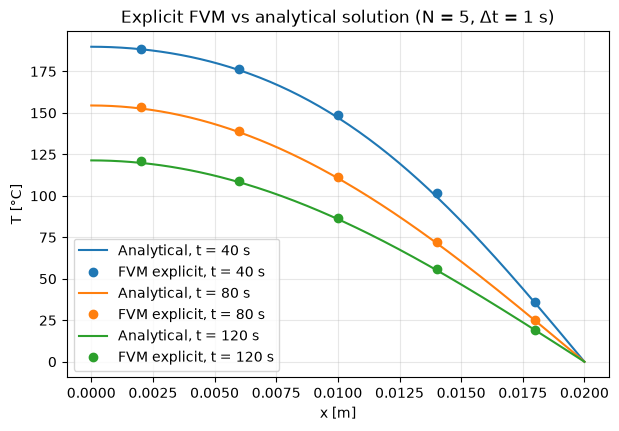

In [17]:
x_plot = np.linspace(0, 0.02, 200)
colors = ["C0", "C1", "C2"]

plt.figure(figsize=(7, 4.5))
for i in range(len(rod_history.frames)):
    t, T_num = rod_history.frames[i]
    T_exact = analytical_T(x_plot, t, L=0.02, alpha=10 / 1e7, n_terms=100)
    plt.plot(x_plot, T_exact, color=colors[i], label=f"Analytical, t = {t} s")
    plt.plot(xs, T_num, "o", color=colors[i], label=f"FVM explicit, t = {t} s")

plt.xlabel("x [m]")
plt.ylabel("T [°C]")
plt.title("Explicit FVM vs analytical solution (N = 5, Δt = 1 s)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Even though the above looks exact, we have to measure the accuracy. We compare the numerical $T_i$ with the analytical solution at the same node positions, and take the largest absolute difference at each time.
$$ E(t) = \max_i \left| T_i(t) - T(x_i, t) \right| $$

In [18]:
for i in range(len(rod_history.frames)):
    t, T_num = rod_history.frames[i]
    t_exact, T_exact = analytical_frames[i]
    error = np.max(np.abs(T_num - T_exact))
    print(f"t = {t} s: max error = {error:.2f} °C")

t = 40 s: max error = 1.99 °C
t = 80 s: max error = 0.93 °C
t = 120 s: max error = 0.91 °C


The largest error occurs at the first saved time, $t = 40\,\mathrm{s}$, at about $2\,{}^\circ\mathrm{C}$, and it drops below $1\,{}^\circ\mathrm{C}$ at $80\,\mathrm{s}$ and $120\,\mathrm{s}$. Relative to the initial temperature of $200\,{}^\circ\mathrm{C}$ this is about $1\%$. Using more cells should reduce the error further.